# Lab 12 - 16.10.26
## Machine Learning Lab - BCSE209P
### Kanad Bhattacharya, 23BCE1265

#### Question

    Implement the Q-Learning algorithm to train an agent to reach a goal state
    in a grid based environment. Display the updated Q-table and the optimal
    path.

    No. of states = 5
    Goal state: 3
    No. of actions = 2 (0 = Left, 1 = Right)
    Initialize Q-table with zeros.

    Learning parameters
    alpha = 0.1
    gamma = 0.9 (Discount factor)
    epsilon = 0.2 (Exploration probability)
    episodes = 50

### Q-Learning - Grid world navigation

#### Environment setup

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
import pandas as pd

random.seed(1265)
np.random.seed(1265)

n_states = 5
goal_state = 3
n_actions = 2  # 0 = Left, 1 = Right

Q = np.zeros((n_states, n_actions))

alpha = 0.1
gamma = 0.9
epsilon = 0.2
episodes = 50

#### Environment step function

In [2]:
def step(state, action):
    if action == 0:
        next_state = max(0, state - 1)
    else:
        next_state = min(n_states - 1, state + 1)
    reward = 1.0 if next_state == goal_state else 0.0
    return next_state, reward

#### Train agent

In [3]:
steps_per_episode = []

for episode in range(episodes):
    state = random.choice([s for s in range(n_states) if s != goal_state])
    steps = 0

    while state != goal_state and steps < 100:
        # Epsilon-greedy action selection
        if random.random() < epsilon:
            action = random.choice(range(n_actions))
        else:
            action = int(np.argmax(Q[state]))

        next_state, reward = step(state, action)

        # Q-learning update rule
        Q[state, action] += alpha * (reward + gamma * np.max(Q[next_state]) - Q[state, action])

        state = next_state
        steps += 1

    steps_per_episode.append(steps)

#### Updated Q-table

In [4]:
q_table = pd.DataFrame(Q, columns=['Left (0)', 'Right (1)'])
q_table.index.name = 'State'
q_table

,Left (0),Right (1)
State,,
0,0.000000,0.382609
1,0.046826,0.766221
2,0.269360,0.983577
3,0.000000,0.000000
4,0.651322,0.017100


#### Visualize training progress

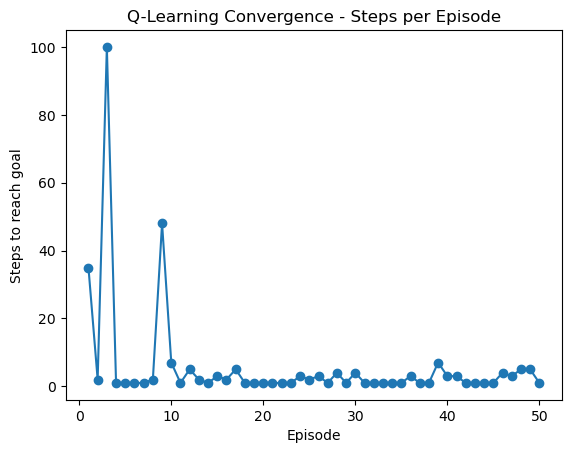

In [5]:
plt.plot(range(1, episodes + 1), steps_per_episode, marker='o')
plt.xlabel('Episode')
plt.ylabel('Steps to reach goal')
plt.title('Q-Learning Convergence - Steps per Episode')
plt.show()

#### Optimal path

In [6]:
policy = np.argmax(Q, axis=1)
print("Learned policy (0=Left, 1=Right):", policy)

def get_optimal_path(start_state, max_steps=20):
    state = start_state
    path = [state]
    for _ in range(max_steps):
        if state == goal_state:
            break
        action = policy[state]
        state, _ = step(state, action)
        path.append(state)
    return path

for start in range(n_states):
    if start != goal_state:
        print(f"Optimal path from state {start}: {get_optimal_path(start)}")

Learned policy (0=Left, 1=Right): [1 1 1 0 0]
Optimal path from state 0: [0, 1, 2, 3]
Optimal path from state 1: [1, 2, 3]
Optimal path from state 2: [2, 3]
Optimal path from state 4: [4, 3]


#### Visualize results

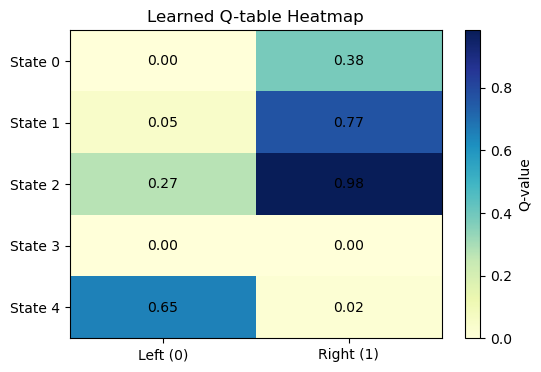

In [7]:
plt.figure(figsize=(6, 4))
plt.imshow(Q, cmap='YlGnBu', aspect='auto')
plt.colorbar(label='Q-value')
plt.xticks([0, 1], ['Left (0)', 'Right (1)'])
plt.yticks(range(n_states), [f"State {s}" for s in range(n_states)])
plt.title('Learned Q-table Heatmap')

for s in range(n_states):
    for a in range(n_actions):
        plt.text(a, s, f"{Q[s, a]:.2f}", ha='center', va='center', color='black')

plt.show()

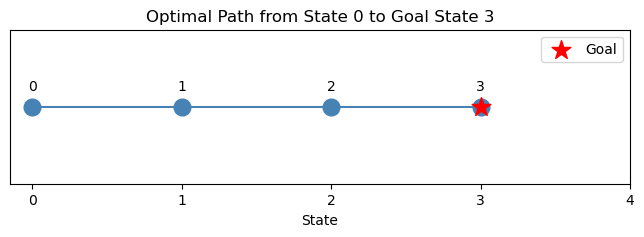

In [8]:
path_from_0 = get_optimal_path(0)

plt.figure(figsize=(8, 2))
plt.plot(path_from_0, [0] * len(path_from_0), marker='o', color='steelblue', markersize=12)
for i, s in enumerate(path_from_0):
    plt.annotate(str(s), (s, 0), textcoords="offset points", xytext=(0, 12), ha='center')
plt.scatter([goal_state], [0], color='red', s=200, marker='*', label='Goal', zorder=3)
plt.yticks([])
plt.xticks(range(n_states))
plt.xlabel('State')
plt.title('Optimal Path from State 0 to Goal State 3')
plt.legend()
plt.show()